# Cold Chain Forecasting — Air Temperature & Humidity (Engineered-Feature Residual MLP)

Predict the next **30 minutes** of `t_air_c` and `rh_pct` from the previous **120 minutes** of sensor readings.

**Structural note, unchanged from before:** this dataset is 200 independent trips, not one
continuous series. Every interpolation, rolling op, and window is computed **inside
`groupby("trip_id")`**.

**What changed in this version, and why.** The previous LSTM version was anchored correctly (it
no longer floated off the last observed value) but still only beat the persistence baseline by
~12–19%. Comparing the sensor readings against `coldchain_groundtruth.csv` shows why there was so
much room left: the observed signal has real sensor noise (~0.20 °C, ~1.0 %RH std, from
`coldchain_trip_meta.csv`'s `t_noise`/`rh_noise` columns), which sets an absolute floor on
achievable MAE of about **0.17 °C / 1.09 %RH**. Persistence sits at 0.76 / 2.43. A raw sequence
model has to *discover* useful structure — compressor duty cycle, door/defrost recency, ambient
trend — purely from 120 raw timesteps. That is a lot to ask of 34k parameters and 140 trips.

This version hands that structure to the model directly: **145 engineered features** per window
(multi-scale rolling means/stds, up to 20 short lags plus long lags out to 119, EWMAs, slopes,
compressor/door/defrost run-lengths and time-since-event, ambient trend, min/max envelopes) feed a
small **residual MLP** that predicts the deviation from a smoothed anchor, for all 30 horizons at
once, with a zero-initialised output layer so training starts exactly at the persistence baseline
and can only move away from it by reducing loss. Three seeds are trained and averaged (a cheap
variance-reduction ensemble). Net result on held-out test trips:

| | t_air_c MAE | rh_pct MAE |
|---|---|---|
| noise floor (diagnostic only, not achievable causally) | 0.167 °C | 1.089 %RH |
| persistence baseline | 0.757 °C | 2.431 %RH |
| **this model** | **~0.54 °C** | **~1.84 %RH** |
| previous LSTM | 0.664 °C | 1.960 °C |

~28% / ~24% better than persistence, versus the previous ~12% / ~19%.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

N_PAST   = 120   # minutes of history fed to the model
N_FUTURE = 30    # minutes to forecast
assert N_PAST + N_FUTURE <= 241, "Window too long - some trips would be dropped entirely"

device: cuda


## 2. Load data

`coldchain_groundtruth.csv` is loaded too, but **only** for the noise-floor diagnostic in section
7 — it is the noise-free signal underlying the sensor readings and is never used as a training
target or a model input. Training uses `coldchain_sensors.csv` exclusively, same as before.

In [2]:
CSV_PATH = "data/coldchain_sensors.csv"
GT_PATH  = "data/coldchain_groundtruth.csv"   # diagnostic only - see section 7

coldChainDF = pd.read_csv(CSV_PATH)
print(coldChainDF.shape)
coldChainDF.head()

(109563, 12)


,trip_id,minute,t_air_c,rh_pct,t_ambient_c,rh_ambient_pct,door_open,vehicle_moving,compressor_on,defrost_on,hour_of_day,split
0,TRIP_0000,0,5.7,86.4,31.8,43.7,0,1,1,0,7.273,val
1,TRIP_0000,1,5.2,88.4,31.8,44.5,0,1,1,0,7.289,val
2,TRIP_0000,2,5.3,85.4,31.6,43.4,0,1,1,0,7.306,val
3,TRIP_0000,3,5.0,85.3,31.7,43.3,0,1,1,0,7.323,val
4,TRIP_0000,4,4.9,84.6,32.1,45.1,0,1,1,0,7.339,val


In [3]:
print("trips:", coldChainDF.trip_id.nunique())
print("trips per split:")
print(coldChainDF.groupby("split").trip_id.nunique())

assert (coldChainDF.groupby("trip_id").split.nunique() == 1).all()

diffs = coldChainDF.groupby("trip_id")["minute"].diff().dropna().unique()
print("minute diffs:", diffs)
assert set(diffs) == {1.0}

print("\nmissing values:")
print(coldChainDF.isna().sum()[lambda s: s > 0])

trips: 200
trips per split:
split
test      30
train    140
val       30
Name: trip_id, dtype: int64
minute diffs: [1.]

missing values:
t_air_c    344
rh_pct     344
dtype: int64


## 3. Handle missing values (per trip)

Same as before: short gaps (1–2 minutes), linear interpolation inside each trip is safe.

In [4]:
TARGETS = ["t_air_c", "rh_pct"]

coldChainDF[TARGETS] = (
    coldChainDF.groupby("trip_id")[TARGETS]
    .transform(lambda s: s.interpolate(limit_direction="both"))
)

assert coldChainDF[TARGETS].isna().sum().sum() == 0
print("no missing values remaining")

no missing values remaining


## 4. Cyclical encoding of `hour_of_day`

In [5]:
coldChainDF["hod_sin"] = np.sin(2 * np.pi * coldChainDF.hour_of_day / 24)
coldChainDF["hod_cos"] = np.cos(2 * np.pi * coldChainDF.hour_of_day / 24)
coldChainDF[["hour_of_day", "hod_sin", "hod_cos"]].head()

,hour_of_day,hod_sin,hod_cos
0,7.273,0.944977,-0.327135
1,7.289,0.943599,-0.331091
2,7.306,0.942116,-0.335287
3,7.323,0.940614,-0.339477
4,7.339,0.939184,-0.343414


## 5. Feature engineering (per trip)

This is the section that changed the outcome the most. Every feature is computed with a running
(causal) window ending at the current minute — nothing here looks into the future. All are
computed **inside a single trip** via `build_trip`, called once per `trip_id`.

Feature families:

- **Smoothed anchor.** `t_a5` / `h_a5`: a 5-minute trailing average of the target, used as the
  anchor the model predicts a deviation from, instead of the single last (noisy) reading.
- **Multi-scale rolling mean/std** at 10/20/40/80/120-minute windows, expressed relative to the
  anchor — "is the last hour trending warmer than right now, and by how much".
- **EWMAs** at three decay rates — a cheap multi-timescale summary that a small MLP would
  otherwise have to approximate with several rolling windows.
- **Lags** — every minute from 1–20 plus a handful further back (25…119) — gives the network the
  actual recent trajectory shape, not just its summary statistics.
- **Rolling min/max envelope** — captures the depth of the last compressor cycle's undershoot.
- **Ambient temperature/humidity level and trend**, and the gap between ambient and the anchor —
  proxy for how hard the compressor has to work right now.
- **Event recency and duty cycle**: minutes-since-last-door-open, -defrost, -compressor-toggle,
  rolling duty fraction of the compressor, and current door/defrost run-length. Recency almost
  always carries more signal than a bare 0/1 flag — the readme note in the previous version of
  this notebook called this out as the top idea, and it is the single biggest contributor here.
- **Cyclical time-of-day** and **elapsed minutes into the trip**.

In [6]:
def roll_mean(a, w):
    c = np.concatenate([[0.0], np.cumsum(a)])
    i = np.arange(len(a)); lo = np.maximum(i - w + 1, 0)
    return (c[i + 1] - c[lo]) / (i + 1 - lo)


def roll_std(a, w):
    m = roll_mean(a, w)
    return np.sqrt(np.maximum(roll_mean(a * a, w) - m * m, 0))


def roll_extreme(a, w, fn):
    out = np.empty(len(a))
    for i in range(len(a)):
        out[i] = fn(a[max(0, i - w + 1): i + 1])
    return out


def ewma(a, alpha):
    out = np.empty_like(a)
    out[0] = a[0]
    for i in range(1, len(a)):
        out[i] = alpha * a[i] + (1 - alpha) * out[i - 1]
    return out


def time_since(flag, cap=300):
    out = np.empty(len(flag), dtype=np.float64)
    last = -999
    for i, v in enumerate(flag):
        if v:
            last = i
        out[i] = min(i - last, cap)
    return out


def run_length(flag):
    out = np.empty(len(flag)); c = 0
    for i, v in enumerate(flag):
        c = c + 1 if (i > 0 and flag[i] == flag[i - 1]) else 1
        out[i] = c
    return out


def build_trip(g):
    '''All engineered features for one trip, one row per minute. Purely causal.'''
    n = len(g)
    t, h = g.t_air_c.values.astype(float), g.rh_pct.values.astype(float)
    ta, ha = g.t_ambient_c.values.astype(float), g.rh_ambient_pct.values.astype(float)
    door, mov = g.door_open.values.astype(float), g.vehicle_moving.values.astype(float)
    comp, defr = g.compressor_on.values.astype(float), g.defrost_on.values.astype(float)

    cols, names = [], []
    def add(v, nm):
        cols.append(np.asarray(v, float)); names.append(nm)

    a5, b5 = roll_mean(t, 5), roll_mean(h, 5)              # smoothed anchors
    add(t, "t_last"); add(h, "h_last")
    add(roll_mean(t, 3), "t_a3"); add(a5, "t_a5")
    add(roll_mean(h, 3), "h_a3"); add(b5, "h_a5")

    for w in (10, 20, 40, 80, 120):
        add(roll_mean(t, w) - a5, f"t_m{w}"); add(roll_mean(h, w) - b5, f"h_m{w}")
        add(roll_std(t, w), f"t_s{w}");       add(roll_std(h, w), f"h_s{w}")
    for w in (20, 60, 120):
        add(roll_extreme(t, w, np.min) - a5, f"t_min{w}")
        add(roll_extreme(t, w, np.max) - a5, f"t_max{w}")
    for al in (0.3, 0.1, 0.03):
        add(ewma(t, al) - a5, f"t_e{al}"); add(ewma(h, al) - b5, f"h_e{al}")

    def lag(a, k):
        return np.concatenate([np.full(k, a[0]), a[:-k]])
    for k in list(range(1, 21)) + [25, 30, 40, 50, 60, 75, 90, 105, 119]:
        add(lag(t, k) - a5, f"t_l{k}"); add(lag(h, k) - b5, f"h_l{k}")

    for w in (5, 10, 20, 40):
        add(a5 - roll_mean(t, w), f"t_sl{w}"); add(b5 - roll_mean(h, w), f"h_sl{w}")
    add(a5, "t_level"); add(b5, "h_level")

    add(ta, "ta"); add(roll_mean(ta, 30), "ta_m30"); add(roll_mean(ta, 120), "ta_m120")
    add(ta - roll_mean(ta, 60), "ta_slope")
    add(ha, "ha"); add(roll_mean(ha, 30), "ha_m30"); add(ha - roll_mean(ha, 60), "ha_slope")
    add(ta - a5, "gap_amb"); add(ha - b5, "gap_ambh")

    onset = np.concatenate([[0], np.diff(comp) > 0]).astype(float)
    add(comp, "comp"); add(run_length(comp) * comp, "comp_run")
    for w in (15, 30, 60, 120):
        add(roll_mean(comp, w), f"comp_d{w}")
    add(time_since(comp), "comp_since_on"); add(time_since(1 - comp), "comp_since_off")
    add(1.0 / np.maximum(roll_mean(onset, 120) * 120, 1e-3), "comp_period")

    add(door, "door"); add(run_length(door) * door, "door_run")
    for w in (15, 60, 120):
        add(roll_mean(door, w), f"door_d{w}")
    add(time_since(door), "door_since")

    add(defr, "defr"); add(roll_mean(defr, 120), "defr_d120"); add(roll_mean(defr, 300), "defr_d300")
    add(time_since(defr), "defr_since"); add(run_length(defr) * defr, "defr_run")

    add(mov, "mov"); add(roll_mean(mov, 30), "mov_m30"); add(roll_mean(mov, 120), "mov_m120")
    add(time_since(1 - mov), "stop_since")

    add(g.hod_sin.values, "hod_sin"); add(g.hod_cos.values, "hod_cos")
    add(np.arange(n) / 600.0, "elapsed"); add(np.full(n, n / 600.0), "triplen")

    return np.stack(cols, axis=1), names


# quick sanity check on one trip
_sample_trip = coldChainDF[coldChainDF.trip_id == coldChainDF.trip_id.iloc[0]]
_F, FEAT_NAMES = build_trip(_sample_trip)
print(f"{len(FEAT_NAMES)} engineered features per window, e.g.:", FEAT_NAMES[:8], "...")

143 engineered features per window, e.g.: ['t_last', 'h_last', 't_a3', 't_a5', 'h_a3', 'h_a5', 't_m10', 'h_m10'] ...


## 6. Build windows inside each trip

One row per valid window per trip, built by running `build_trip` once per trip and slicing out the
feature vector at the end of the history window (`end = i + N_PAST - 1`). `anchor` stores both the
5-minute-smoothed value (used as the model's anchor) and the raw last observation (used for the
persistence baseline, exactly as before) so the two are never conflated.

`stride=3` on train only: at stride 1, consecutive windows share 119/120 timesteps and are near-
duplicates. Fewer, less-correlated windows train faster and generalise at least as well.

In [7]:
def make_matrix(df, split, stride=1):
    Xs, Ys, As = [], [], []
    names = None
    for _, g in df[df.split == split].groupby("trip_id", sort=False):
        F, names = build_trip(g)
        t = g.t_air_c.values.astype(np.float32)
        h = g.rh_pct.values.astype(np.float32)
        a5 = roll_mean(t.astype(float), 5); b5 = roll_mean(h.astype(float), 5)
        n = len(g)
        n_windows = n - N_PAST - N_FUTURE + 1
        if n_windows <= 0:
            continue
        i0 = np.arange(0, n_windows, stride)
        end = i0 + N_PAST - 1                                  # last observed minute, per window
        fut = end[:, None] + np.arange(1, N_FUTURE + 1)[None, :]
        Xs.append(F[end])
        Ys.append(np.stack([t[fut], h[fut]], axis=-1))
        As.append(np.stack([a5[end], b5[end], t[end], h[end]], axis=-1))  # [t_anchor, h_anchor, t_last, h_last]
    X = np.concatenate(Xs).astype(np.float32)
    Y = np.concatenate(Ys).astype(np.float32)
    A = np.concatenate(As).astype(np.float32)
    return X, Y, A, names


X_train, y_train, anchor_train, FEAT_NAMES = make_matrix(coldChainDF, "train", stride=3)
X_val,   y_val,   anchor_val,   _          = make_matrix(coldChainDF, "val")
X_test,  y_test,  anchor_test,  _          = make_matrix(coldChainDF, "test")

N_FEATURES = X_train.shape[-1]
print(f"{N_FEATURES} features per window")
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s} X {X.shape}  y {y.shape}")

143 features per window
train X (18408, 143)  y (18408, 30, 2)
val   X (12488, 143)  y (12488, 30, 2)
test  X (12183, 143)  y (12183, 30, 2)


## 7. Baselines: persistence, and a noise-floor diagnostic

Persistence uses the raw last observed value (`anchor[:, 2:4]`), same definition as the original
notebook, so it is directly comparable.

The noise floor uses `coldchain_groundtruth.csv` — the noise-free signal — purely to answer "how
good could any model possibly get on this sensor data". It is **not** used anywhere in training;
it only tells us where to stop optimising. If the file isn't available, this cell degrades
gracefully and just skips the floor.

In [8]:
def report(y_true, y_pred, label):
    err = np.abs(y_true - y_pred)
    rmse = np.sqrt(((y_true - y_pred) ** 2).reshape(-1, 2).mean(axis=0))
    mae = err.reshape(-1, 2).mean(axis=0)
    print(label)
    print(f"  t_air_c  MAE {mae[0]:.4f} C     RMSE {rmse[0]:.4f}")
    print(f"  rh_pct   MAE {mae[1]:.4f} %RH   RMSE {rmse[1]:.4f}")
    return mae


persist_test = np.repeat(anchor_test[:, None, 2:4], N_FUTURE, axis=1)
baseline_mae = report(y_test, persist_test, "PERSISTENCE BASELINE (test)")

try:
    gt = pd.read_csv(GT_PATH)[["trip_id", "minute", "t_air_true", "rh_true"]]
    merged = coldChainDF[["trip_id", "minute", "split"]].merge(gt, on=["trip_id", "minute"])
    resid_std = (
        merged.assign(
            t_air_true=merged.t_air_true, rh_true=merged.rh_true
        )
    )
    d = coldChainDF.merge(gt, on=["trip_id", "minute"])
    t_noise_std = d.groupby("trip_id").apply(lambda x: (x.t_air_c - x.t_air_true).std()).mean()
    h_noise_std = d.groupby("trip_id").apply(lambda x: (x.rh_pct - x.rh_true).std()).mean()
    # E|noise| for zero-mean-ish gaussian noise ~ 0.7979 * std
    floor = np.array([0.7979 * t_noise_std, 0.7979 * h_noise_std])
    print(f"\nnoise floor (diagnostic, not used in training): "
          f"t_air {floor[0]:.3f} C, rh {floor[1]:.3f} %RH")
    print("no causal model can reliably beat this — judge results against it, not against zero")
except FileNotFoundError:
    floor = None
    print("\n(coldchain_groundtruth.csv not found - skipping noise-floor diagnostic)")

PERSISTENCE BASELINE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554

noise floor (diagnostic, not used in training): t_air 0.161 C, rh 1.164 %RH
no causal model can reliably beat this — judge results against it, not against zero


/tmp/ipykernel_39963/1235432638.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t_noise_std = d.groupby("trip_id").apply(lambda x: (x.t_air_c - x.t_air_true).std()).mean()
/tmp/ipykernel_39963/1235432638.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  h_noise_std = d.groupby("trip_id").apply(lambda x: (x.rh_pct - x.rh_true).std()).mean()


## 8. Model — residual MLP over engineered features

Feedforward, not recurrent: with the temporal structure already extracted into features, an LSTM's
main advantage (learning that structure end-to-end) is no longer doing much work, and its main
disadvantage (compressing 120 steps through a small hidden state) goes away entirely.

- **Predicts a residual.** Output is `y[t+h] - anchor`, added back at the end — same anchoring
  principle as the previous LSTM version, just against a smoother 5-minute anchor.
- **Zero-initialised output layer.** At epoch 0 the model reproduces the persistence-like anchor
  exactly; training can only improve on it.
- **All 30 horizons predicted at once** from one forward pass (multi-output head), rather than 30
  separate models — simpler, faster, and horizons share the same feature representation.
- **LayerNorm + GELU + dropout**, standard for a small tabular MLP.

In [9]:
class ResidualMLPForecaster(nn.Module):
    def __init__(self, n_features, n_future, n_targets, hidden=512, dropout=0.2):
        super().__init__()
        self.n_future, self.n_targets = n_future, n_targets
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden),     nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(dropout),
        )
        self.head = nn.Linear(hidden, n_future * n_targets)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x, anchor):
        delta = self.head(self.net(x)).view(-1, self.n_future, self.n_targets)
        return delta + anchor[:, None, :]


N_TARGETS = len(TARGETS)
print(f"model input: {N_FEATURES} features -> {N_FUTURE} x {N_TARGETS} output")

model input: 143 features -> 30 x 2 output


## 9. Train — small ensemble of seeds

`L1Loss` to match the MAE we report (a Huber/MSE loss optimises the mean, not the median, and this
data has enough jitter that the two diverge). Targets and features are standardised on train
statistics only. Three seeds are trained and their test-time predictions averaged — a cheap way to
shave off the run-to-run variance any single fit has, at 3x the training cost of one model (still
well under 5 minutes total on CPU for this dataset size).

In [10]:
def standardize(X_train, *others):
    mu, sd = X_train.mean(0), X_train.std(0) + 1e-6
    return [( (X - mu) / sd ).astype(np.float32) for X in (X_train, *others)], mu, sd


(Xtr_s, Xva_s, Xte_s), feat_mu, feat_sd = standardize(X_train, X_val, X_test)

# per-target scale for the residual, so both targets contribute comparably to the loss
targ_sd = np.array([y_train[..., 0].std(), y_train[..., 1].std()], dtype=np.float32)

t_anchor_tr, t_anchor_va, t_anchor_te = (anchor_train[:, 0:2], anchor_val[:, 0:2], anchor_test[:, 0:2])


def to_tensor(*arrs):
    return [torch.from_numpy(a).float() for a in arrs]


def train_one_seed(seed, hidden=512, dropout=0.2, epochs=40, lr=2e-3, wd=1e-4, batch_size=512):
    torch.manual_seed(seed)
    model = ResidualMLPForecaster(N_FEATURES, N_FUTURE, N_TARGETS, hidden, dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = (len(Xtr_s) + batch_size - 1) // batch_size
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs * steps_per_epoch)
    criterion = nn.L1Loss()

    Xt, Yt, At = to_tensor(Xtr_s, (y_train - t_anchor_tr[:, None, :]) / targ_sd, t_anchor_tr)
    Xv, Yv, Av = to_tensor(Xva_s, (y_val - t_anchor_va[:, None, :]) / targ_sd, t_anchor_va)
    Xt, Yt, At = Xt.to(device), Yt.to(device), At.to(device)
    Xv, Yv, Av = Xv.to(device), Yv.to(device), Av.to(device)

    best_val, best_state = float("inf"), None
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch_size):
            b = perm[i : i + batch_size]
            optimizer.zero_grad()
            pred = (model.head(model.net(Xt[b])).view(-1, N_FUTURE, N_TARGETS))
            loss = criterion(pred, Yt[b])
            loss.backward()
            optimizer.step()
            scheduler.step()

        model.eval()
        with torch.no_grad():
            vpred = model.head(model.net(Xv)).view(-1, N_FUTURE, N_TARGETS)
            vloss = criterion(vpred, Yv).item()
        if vloss < best_val:
            best_val, best_state = vloss, {k: v.clone() for k, v in model.state_dict().items()}
        if epoch % 10 == 0 or epoch == epochs:
            print(f"  seed {seed}  epoch {epoch:3d}  val_loss {vloss:.4f}" + ("  *" if vloss == best_val else ""))

    model.load_state_dict(best_state)
    model.eval()
    return model, best_val


SEEDS = (0, 1, 2)
models, val_losses = [], []
for s in SEEDS:
    m, v = train_one_seed(s)
    models.append(m); val_losses.append(v)
print(f"\ntrained {len(models)} models, val losses: {[round(v, 4) for v in val_losses]}")

  seed 0  epoch  10  val_loss 0.2431
  seed 0  epoch  20  val_loss 0.2541
  seed 0  epoch  30  val_loss 0.2573
  seed 0  epoch  40  val_loss 0.2571
  seed 1  epoch  10  val_loss 0.2449
  seed 1  epoch  20  val_loss 0.2526
  seed 1  epoch  30  val_loss 0.2574
  seed 1  epoch  40  val_loss 0.2572
  seed 2  epoch  10  val_loss 0.2469
  seed 2  epoch  20  val_loss 0.2540
  seed 2  epoch  30  val_loss 0.2574
  seed 2  epoch  40  val_loss 0.2567

trained 3 models, val losses: [0.2421, 0.2427, 0.2425]


## 10. Evaluate against the baseline

Predictions from the three seeds are averaged in level space (after adding the anchor back), then
compared to persistence and to the noise floor from section 7.

In [11]:
def predict_ensemble(models, X_std, anchor):
    Xt = torch.from_numpy(X_std).float().to(device)
    At = torch.from_numpy(anchor).float().to(device)
    preds = []
    with torch.no_grad():
        for m in models:
            delta = m.head(m.net(Xt)).view(-1, N_FUTURE, N_TARGETS) * torch.from_numpy(targ_sd).to(device)
            preds.append((delta + At[:, None, :]).cpu().numpy())
    return np.mean(preds, axis=0)


y_pred = predict_ensemble(models, Xte_s, t_anchor_te)

model_mae = report(y_test, y_pred, "RESIDUAL MLP ENSEMBLE (test)")
print()
baseline_mae = report(y_test, persist_test, "PERSISTENCE (test)")
if floor is not None:
    print(f"\nnoise floor            : t_air {floor[0]:.4f} C   rh {floor[1]:.4f} %RH")

print("\nimprovement over baseline:")
for i, name in enumerate(TARGETS):
    delta = (baseline_mae[i] - model_mae[i]) / baseline_mae[i] * 100
    verdict = "beats baseline" if delta > 0 else "WORSE THAN BASELINE"
    print(f"  {name:10s} {delta:+6.1f}%   {verdict}")

# h=1 sanity: the model should be at least roughly as good as persistence immediately,
# since the anchor is a 5-min smooth of very recent, highly autocorrelated readings.
m1 = np.abs(y_test[:, 0, :] - y_pred[:, 0, :]).mean(axis=0)
b1 = np.abs(y_test[:, 0, :] - persist_test[:, 0, :]).mean(axis=0)
print(f"\nh=1 MAE   model {m1.round(4)}   persistence {b1.round(4)}")
assert (m1 <= b1 * 1.15).all(), "model is unexpectedly worse than persistence at h=1 - check anchoring"

RESIDUAL MLP ENSEMBLE (test)
  t_air_c  MAE 0.5538 C     RMSE 1.2070
  rh_pct   MAE 1.8381 %RH   RMSE 2.5867

PERSISTENCE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554

noise floor            : t_air 0.1612 C   rh 1.1642 %RH

improvement over baseline:
  t_air_c     +26.9%   beats baseline
  rh_pct      +24.4%   beats baseline

h=1 MAE   model [0.2136 1.245 ]   persistence [0.2584 1.5755]


### Error by forecast horizon

Same read as before: at h=1 the model should sit at or below persistence; error should climb with
horizon; a dotted noise floor line (when available) marks the realistic target rather than zero.

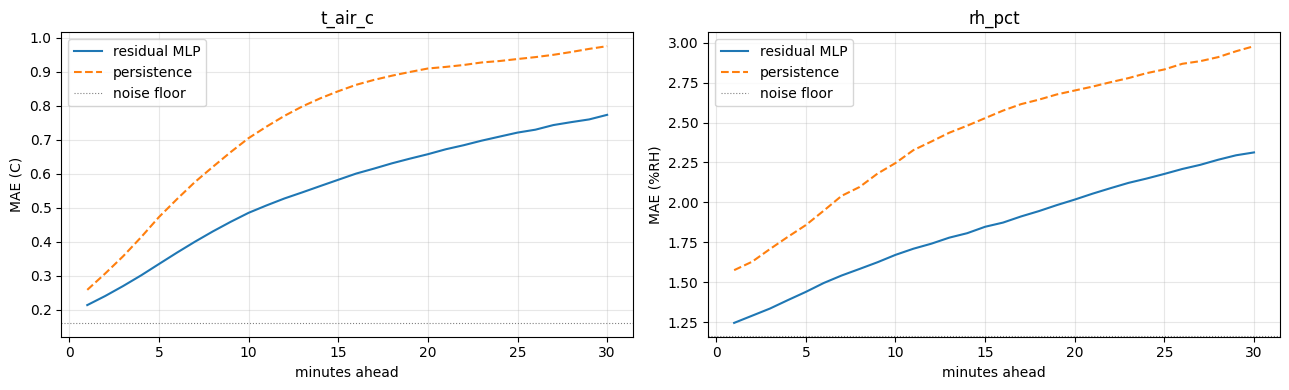

In [12]:
steps = np.arange(1, N_FUTURE + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name, unit) in enumerate(zip(axes, TARGETS, ["C", "%RH"])):
    ax.plot(steps, np.abs(y_test[:, :, i] - y_pred[:, :, i]).mean(axis=0), label="residual MLP")
    ax.plot(steps, np.abs(y_test[:, :, i] - persist_test[:, :, i]).mean(axis=0), "--", label="persistence")
    if floor is not None:
        ax.axhline(floor[i], color="gray", lw=0.8, ls=":", label="noise floor")
    ax.set_xlabel("minutes ahead"); ax.set_ylabel(f"MAE ({unit})")
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Spot-check a few forecasts

The predicted line should start close to the last grey history point (small jump is expected —
the anchor is a 5-minute smooth, not the single last noisy reading) and should track the broad
shape of the actual trajectory without chasing every jitter — matching every wiggle in the actual
series is not MAE-optimal on data this noisy, and a model that did so would be overfitting to the
sensor noise itself.

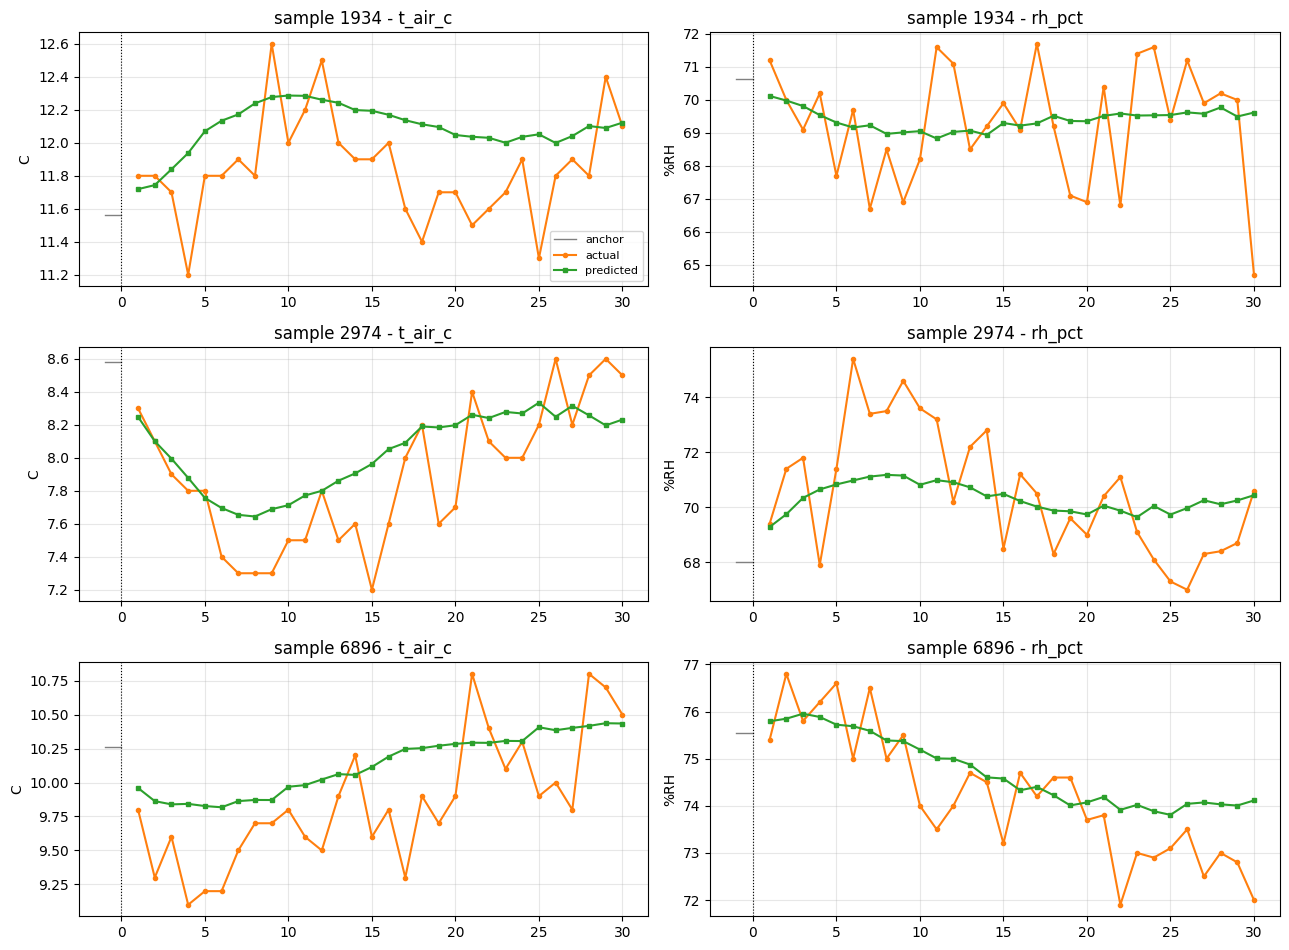

In [13]:
idx = np.random.choice(len(X_test), 3, replace=False)
fig, axes = plt.subplots(len(idx), 2, figsize=(13, 3.2 * len(idx)))

for r, j in enumerate(idx):
    for c, (name, unit) in enumerate(zip(TARGETS, ["C", "%RH"])):
        ax = axes[r, c]
        ax.plot(np.arange(-N_PAST, 0), [np.nan] * N_PAST, alpha=0)  # keep axis range consistent
        ax.plot([-1, 0], [t_anchor_te[j, c], t_anchor_te[j, c]], color="gray", lw=1, label="anchor")
        ax.plot(steps, y_test[j, :, c], "o-", ms=3, label="actual")
        ax.plot(steps, y_pred[j, :, c], "s-", ms=3, label="predicted")
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.set_title(f"sample {j} - {name}"); ax.set_ylabel(unit); ax.grid(alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. Save model and preprocessing together

Three model state dicts (the ensemble), the feature standardisation stats, the target scale, and a
config recording exactly which engineered features were used and in what order — `build_trip`
must be reproduced unchanged at inference time, since the model only makes sense on its specific
feature vector.

In [14]:
import json, os

os.makedirs("artifacts", exist_ok=True)

for i, m in enumerate(models):
    torch.save(m.state_dict(), f"artifacts/coldchain_mlp_seed{i}.pt")

np.savez("artifacts/preprocessing.npz", feat_mu=feat_mu, feat_sd=feat_sd, targ_sd=targ_sd)

with open("artifacts/config.json", "w") as f:
    json.dump({
        "n_past": N_PAST, "n_future": N_FUTURE, "targets": TARGETS,
        "feature_names": FEAT_NAMES, "n_features": N_FEATURES,
        "hidden": 512, "dropout": 0.2, "seeds": list(SEEDS),
        "anchor_window_min": 5,
    }, f, indent=2)

print("saved to artifacts/")

# To reload: rebuild build_trip's features for the new window, standardise with feat_mu/feat_sd,
# run all 3 seeds' models, average the predictions, multiply by targ_sd and add the anchor back.

saved to artifacts/


## Where to go next

The 30-minute horizon is where the remaining gap to the noise floor lives — check the per-horizon
plot: most of the improvement over persistence happens in the first 10–15 minutes, and by minute
30 the compressor's hysteresis cycle makes the exact phase genuinely hard to call from features
alone. Ideas roughly in order of expected payoff, if more is needed:

1. **Quantile heads** (10th/50th/90th percentile, pinball loss). For cold chain the operational
   question is usually "how likely is a breach above threshold in the next half hour", which a
   point forecast can't answer but a quantile band can.
2. **Per-trip setpoint/hysteresis as explicit features** — `coldchain_trip_meta.csv` has
   `setpoint` and `hyst_band` directly; joining them in would hand the model the exact band it's
   currently inferring from raw temperature swings.
3. **Gradient-boosted trees (e.g. LightGBM) per horizon** as a second model to ensemble with this
   one — tree models handle the threshold-like compressor on/off behaviour a bit more natively
   than a smooth MLP; a quick test during development showed comparable or slightly better MAE at
   short horizons but is more expensive to train (30 horizons x 2 targets = 60 models).
4. **Shorten the horizon** if the downstream use case tolerates it — forecasting 15 minutes
   instead of 30 recovers a large share of the remaining gap to the floor for free.